In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('./dataset.csv')

In [3]:
# Step 1 -> convert text to numbers using textVocab
from tensorflow.keras.layers import TextVectorization

vectorize_layer = TextVectorization(
    max_tokens=100,
    split="character",
    output_mode = 'int',
)

vectorize_layer.adapt(df.encrypt.to_list())

In [4]:
vectorized_strings = np.array([vectorize_layer(s).numpy() for s in df['encrypt']], dtype='object')
vectorized_strings.shape

(34075,)

In [5]:
images = np.array(
    [[vector for _ in range(len(vector))] for vector in vectorized_strings]
, dtype='object')
images.shape

(34075,)

In [6]:
import cv2

X = np.array(
    [cv2.resize(np.array(image, dtype='uint8'), dsize=(64,64)) for image in images]
)
X.shape

(34075, 64, 64)

In [7]:
X = X.reshape(-1,64,64,1)
X.shape

(34075, 64, 64, 1)

In [8]:
input_shape = X[0].shape
input_shape

(64, 64, 1)

In [9]:
y = pd.get_dummies(df[['algorithm']])

In [10]:
X.shape

(34075, 64, 64, 1)

In [11]:
y.shape

(34075, 5)

In [12]:
from sklearn.model_selection import train_test_split
x_train, x_rem, y_train, y_rem = train_test_split(X, y, test_size=0.2, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_rem, y_rem, test_size=0.2, random_state=42)

# Training

In [16]:
import tensorflow as tf
from tensorflow.keras.layers import Lambda, Conv2D, \
BatchNormalization, MaxPool2D, Reshape, Flatten, Dense, Dropout


model = tf.keras.models.Sequential()

model.add(tf.keras.Input(shape=input_shape))

model.add(Conv2D(16, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Conv2D(32, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Flatten())

model.add(Dropout(0.1))
model.add(Dense(units=1024, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=256, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=64, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=16, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(units=5, activation='softmax'))

In [17]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 62, 62, 16)        160       
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 31, 31, 16)       0         
 2D)                                                             
                                                                 
 batch_normalization_7 (Batc  (None, 31, 31, 16)       64        
 hNormalization)                                                 
                                                                 
 dropout_6 (Dropout)         (None, 31, 31, 16)        0         
                                                                 
 conv2d_4 (Conv2D)           (None, 29, 29, 32)        4640      
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 14, 14, 32)      

In [18]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    loss="categorical_crossentropy", metrics=["accuracy"]
)
callback = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        restore_best_weights=True
    )
]

history = model.fit(
    x_train,
    y_train,
    epochs=10000,
    validation_data=(x_val, y_val),
    callbacks=callback,
)

Epoch 1/10000
852/852 [==============================] - 11s 10ms/step - loss: 1.1977 - accuracy: 0.4627 - val_loss: 1.0805 - val_accuracy: 0.5161
Epoch 2/10000
852/852 [==============================] - 9s 10ms/step - loss: 1.0930 - accuracy: 0.5132 - val_loss: 1.0625 - val_accuracy: 0.5174
Epoch 3/10000
852/852 [==============================] - 9s 10ms/step - loss: 1.0494 - accuracy: 0.5465 - val_loss: 0.9777 - val_accuracy: 0.5789
Epoch 4/10000
852/852 [==============================] - 9s 10ms/step - loss: 1.0158 - accuracy: 0.5716 - val_loss: 0.9707 - val_accuracy: 0.5864
Epoch 5/10000
852/852 [==============================] - 8s 10ms/step - loss: 0.9896 - accuracy: 0.5856 - val_loss: 1.0243 - val_accuracy: 0.5668
Epoch 6/10000
852/852 [==============================] - 8s 10ms/step - loss: 0.9701 - accuracy: 0.5977 - val_loss: 0.9334 - val_accuracy: 0.6190
Epoch 7/10000
852/852 [==============================] - 8s 10ms/step - loss: 0.9557 - accuracy: 0.6036 - val_loss: 1.0162 

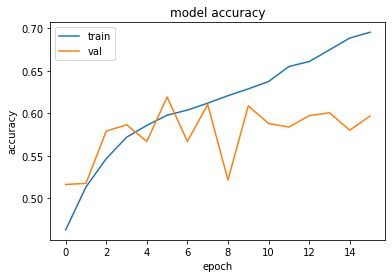

In [19]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

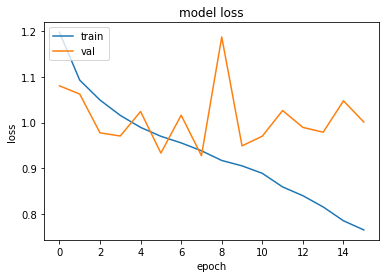

In [20]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [21]:
model.save('./model')

In [22]:
test_loss, test_acc = model.evaluate(x_val, y_val)
print(f"test_loss={test_loss}, test_acc={test_acc}")

171/171 [==============================] - 1s 4ms/step - loss: 0.9334 - accuracy: 0.6190
test_loss=0.9334046244621277, test_acc=0.6190388798713684
